In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("plots.mplstyle")
np.random.seed(42)

In [2]:
amps_array = []
phases_array = []

In [ ]:
import src.heat1D_crank_nicolson_solver as cns

L = 1
Tf = 10
nt = 50000
D = 1
h = 1
wanted_r = 0.5


# Inizializza solver
solver = cns.Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

|---------- Solver info ----------|
Time scale coeff:       1.00e+00
dx:                     2.00e-02
dt:                     2.00e-04
nt:                     50000
nx:                     51
r:                      5.00e-01


In [4]:
from scipy.optimize import curve_fit

nt_fit = 30000 # Select only part of the curve to use in the fit

omegas_array = np.logspace(0,3,10)*1/Tf*2*np.pi

for omega_tmp in omegas_array:
    
    f = np.sin(solver.t_array*omega_tmp)
    g = solver.solve(f)[-1]
    
    beta = np.sqrt(omega_tmp/(2*D))
    p0=[
        omega_tmp, 
        2*np.exp(-beta*L),
        beta*L,
        0
    ]

    t_array_fit = solver.t_array[nt_fit:]

    # Create the function we want to fit
    def my_sin(x, omega, amplitude, phase, offset):
        return np.sin(x * omega - phase) * amplitude + offset

    fit = curve_fit(my_sin, t_array_fit, g[nt_fit:], p0=p0,
        bounds=(
            [0, 0, -np.inf, -np.inf],  
            [np.inf, np.inf, np.inf, np.inf]
        ))

    data_first_guess = my_sin(t_array_fit, *p0)

    data_fit = my_sin(t_array_fit, *fit[0])

    # print(f"fit_freq         = {fit[0][0]:.3e}, theoretical = {omega_tmp:.3e}")
    # print(f"fit_amplitude   = {fit[0][1]:.3e}, theoretical = {2*np.exp(-beta*L):.3e}")
    # print(f"fit_phase       = {fit[0][2]:.3e}, theoretical = {beta*L:.3e}")
    # print(f"fit_offset      = {fit[0][3]:.3e}, theoretical = {0:.3e}")

    amps_array.append(fit[0][1])
    phases_array.append(fit[0][2])

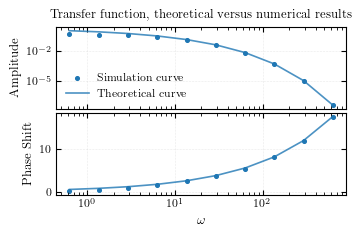

In [7]:
fig, axes = plt.subplots(2,1, sharex=True)

axes[0].scatter(omegas_array, amps_array, label="Simulation curve", s=7)
axes[0].plot(omegas_array, 2*np.exp(-np.sqrt(omegas_array/(2*D))*L), label="Theoretical curve", alpha=0.8)

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_ylabel(r"Amplitude")
axes[0].legend()
#axes[0].tick_params(axis='x', which='both', labelbottom=False)

axes[1].scatter(omegas_array, phases_array, label="Simulation curve", s=7)
axes[1].plot(omegas_array, np.sqrt(omegas_array/(2*D))*L, label="Theoretical curve", alpha=0.8)
axes[1].set_xscale("log")
axes[1].set_ylabel(r"Phase Shift")
axes[1].set_xlabel(r"$\omega$")

axes[0].set_title("Transfer function, theoretical versus numerical results")
axes[0].grid()
axes[1].grid()

plt.savefig("assets/funzione_trasferimento.pdf")
plt.show()